# Load data

In [1]:
import pandas as pd

df = pd.read_csv(r"C:/Users/49dhe/Desktop/project 2/1_DATA/retail_clean.csv",
                 parse_dates=["InvoiceDate"])
df["Invoice"] = df["Invoice"].astype(str)


# Two huge orders (80,995 and 74,215 units) were cancelled minutes later.
# We removed the cancellations in cleaning, so we must remove the originals too.

In [2]:
df = df[~df["Invoice"].isin(["581483", "541431"])]

print(len(df), round(df["Revenue"].sum(), 2))

776575 16822914.77


# RMF Table

In [3]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)
print(len(rfm))
rfm.describe().round(1)

5852


,Recency,Frequency,Monetary
count,5852.0,5852.0,5852.0
mean,200.3,6.3,2874.7
std,208.5,12.7,14108.7
min,1.0,1.0,2.9
25%,25.8,1.0,339.2
50%,95.0,3.0,855.6
75%,379.0,7.0,2237.3
max,739.0,373.0,580987.0


# Score customer 1=5

In [4]:
rfm["R"] = pd.cut(rfm["Recency"], bins=[0, 30, 90, 180, 365, 10000],
                  labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.cut(rfm["Frequency"], bins=[0, 1, 2, 5, 10, 10000],
                  labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.cut(rfm["Monetary"], bins=[0, 300, 700, 1500, 5000, 10000000],
                  labels=[1, 2, 3, 4, 5]).astype(int)
rfm.head()

,Recency,Frequency,Monetary,R,F,M
Customer ID,,,,,,
12346,529,2,169.36,1,2,1
12347,2,8,4921.53,5,4,4
12348,75,5,1658.40,4,3,4
12349,19,3,3678.69,5,3,4
12350,310,1,294.40,2,1,1


# Naming segments

In [5]:
def segment(row):
    r = row["R"]
    f = row["F"]
    if r >= 4 and f >= 4:
        return "Champions"
    elif r >= 4 and f == 1:
        return "New Customers"
    elif r >= 4:
        return "Potential Loyalists"
    elif r == 3 and f >= 3:
        return "Loyal Customers"
    elif r == 3:
        return "Need Attention"
    elif f >= 3:
        return "At Risk"
    else:
        return "Lost"

rfm["Segment"] = rfm.apply(segment, axis=1)

summary = rfm.groupby("Segment").agg(
    Customers=("R", "count"),
    AvgRecency=("Recency", "mean"),
    AvgOrders=("Frequency", "mean"),
    Revenue=("Monetary", "sum"),
)
summary["PctCustomers"] = summary["Customers"] / summary["Customers"].sum() * 100
summary["PctRevenue"] = summary["Revenue"] / summary["Revenue"].sum() * 100
summary.sort_values("Revenue", ascending=False).round(1)

,Customers,AvgRecency,AvgOrders,Revenue,PctCustomers,PctRevenue
Segment,,,,,,
Champions,1406,25.8,16.7,12187935.9,24.0,72.4
At Risk,735,353.1,5.5,1523695.4,12.6,9.1
Potential Loyalists,1111,35.2,3.3,1270301.4,19.0,7.6
Loyal Customers,379,131.3,6.7,896516.5,6.5,5.3
Lost,1646,451.3,1.3,694501.4,28.1,4.1
New Customers,367,44.7,1.0,139314.0,6.3,0.8
Need Attention,208,135.3,1.5,110650.2,3.6,0.7


# save results

In [6]:
rfm.to_csv(r"C:/Users/49dhe/Desktop/project 2/1_DATA/rfm_segments.csv")

# Import matplot and seaborn

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

img = r"C:/Users/49dhe/Desktop/project 2/5_IMAGE/"

# customers vs revenue

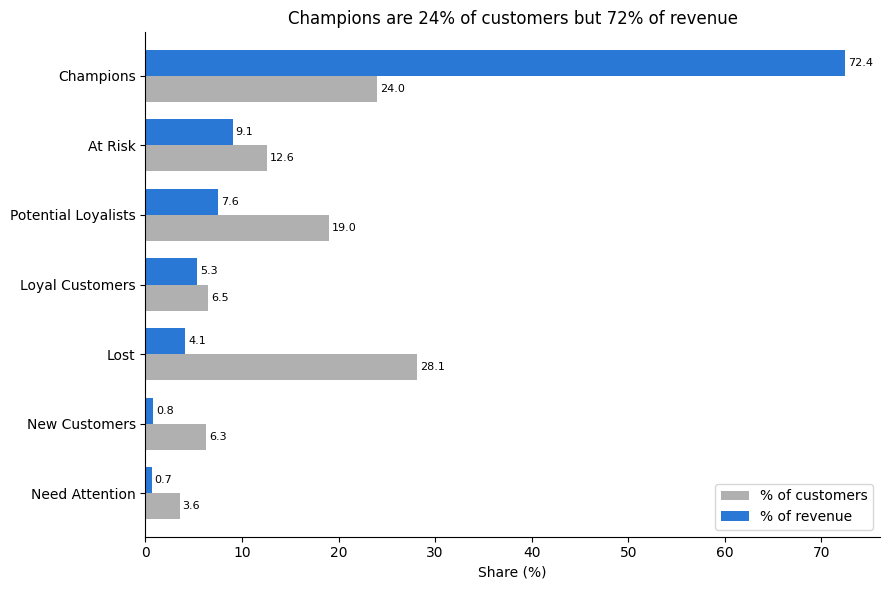

In [8]:
summary = summary.sort_values("PctRevenue")
plot = summary[["PctCustomers", "PctRevenue"]].rename(
    columns={"PctCustomers": "% of customers", "PctRevenue": "% of revenue"})

ax = plot.plot.barh(figsize=(9, 6), color=["#b0b0b0", "#2a78d6"], width=0.75)
ax.set_xlabel("Share (%)")
ax.set_ylabel("")
ax.set_title("Champions are 24% of customers but 72% of revenue")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8, padding=2)
sns.despine()
plt.tight_layout()
plt.savefig(img + "rfm_segments.png", dpi=150)
plt.show()

# File for SQL

In [9]:
   tx = df.assign(Revenue=df["Revenue"].round(2))[["Invoice", "InvoiceDate", "Customer ID", "Revenue"]]
   tx.to_csv(r"C:/Users/49dhe/Desktop/project 2/1_DATA/retail_rfm_input.csv", index=False)
   print(len(tx))

776575
